# 05 — Comparative Modeling, Calibration, and Evaluation

**Research Project:** SE-BRL: A Modality-Aware Social Engineering Behavior Representation Architecture for Explainable Phishing Detection and Risk-Adaptive Defense

**Notebook:** `05_experiments.ipynb`  
**Stage:** Experimental modeling and evaluation  
**Modalities:** Email, Webpage, and URL

## 1. Purpose

This notebook evaluates the detection performance and incremental predictive
utility of Social Engineering Behavior Representation (SE-BRL) features
relative to conventional phishing detection features.

It implements three experimental configurations:

- **E1 — Conventional Baseline:** Models trained on conventional text,
  URL, or webpage characteristics.
- **E2 — Behavioral Representation:** Models trained on rule-derived
  SE-BRL behavioral support and evidence-availability indicators.
- **E3 — Feature Fusion:** Models combining conventional predictors
  with rule-derived SE-BRL behavioral features.

The experiments investigate whether adding behavioral evidence improves
phishing detection while preserving an explicit distinction between
supported, absent, and unavailable behavioral evidence.

## 2. Scope

Four datasets are evaluated:

| Dataset | Modality | Experimental Role |
|---|---|---|
| Consolidated Email | Email | E1, E2, E3 |
| PhiUSIIL | Webpage | E1, E2, E3 |
| ISCX URL2016 | URL | E1; technical-only comparison |
| UCI Phishing Websites | Webpage features | E1; technical-only comparison |

The current ISCX and UCI behavioral feature files contain no available
behavioral evidence. Therefore, E2 and E3 are not evaluated on those
datasets as meaningful behavioral experiments.

## 3. Methodological Qualification

The SE-BRL behavioral features used in this notebook are generated
by deterministic evidence-extraction rules.

They are **rule-derived features**, not predictions from an independently
trained behavioral annotation model.

Accordingly, this notebook measures the utility of the present
rule-derived behavioral representation. It does not establish the
performance of a learned behavioral predictor.

## 4. Expected Outputs

The notebook produces:

1. Data integrity and feature coverage reports.
2. Cross-validation metrics.
3. Selected model configurations and calibrated decision thresholds.
4. Final holdout test metrics.
5. Confusion matrices and precision-recall visualizations.
6. Feature contribution and ablation analyses.
7. Machine-readable tables for the thesis Results and Discussion chapter.

All reported numerical performance results must come from executed
experiments. No expected improvement is presumed.

## 5. Research Questions

**RQ1.** How effectively can conventional predictors distinguish phishing
from legitimate artifacts across the available datasets?

**RQ2.** To what extent can rule-derived SE-BRL behavioral evidence
independently discriminate phishing from legitimate artifacts in
modalities where behavioral evidence is assessable?

**RQ3.** Does combining SE-BRL behavioral representations with conventional
features improve detection performance relative to matched conventional
baselines?

**RQ4.** How do evidence availability, class imbalance, and modality-specific
feature coverage affect experimental performance and interpretation?

## 6. Experimental Hypotheses

- **H1:** Conventional features provide measurable phishing detection
  performance across the evaluated datasets.
- **H2:** Assessable SE-BRL behavioral evidence provides predictive
  information about phishing classification.
- **H3:** Fusing conventional and behavioral representations changes
  predictive performance relative to conventional-only models.

H2 and H3 are empirical questions rather than assumed improvements.

## 7. Evaluation Principles

The primary discrimination metric is **Average Precision (AP)**,
corresponding to area under the non-interpolated precision-recall curve
as implemented by scikit-learn.

Additional metrics include:

- Precision
- Recall
- F1 score
- ROC-AUC
- Balanced accuracy
- Brier score
- Confusion matrix

The positive class is assumed to be `target = 1`, representing phishing.
This interpretation must be verified against the preprocessing codebook
before substantive results are reported.

The notebook preserves previously assigned dataset partitions:

- Development: model training and five-fold cross-validation.
- Calibration: probability calibration, when applicable, and
  decision-threshold selection.
- Test: final untouched holdout evaluation.

The model-selection and calibration procedures are fixed before the
test results are inspected.

In [5]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

cwd = Path.cwd().resolve()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent.parent
elif cwd.name == "experiments":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"

PREPROCESSED_DIR = (
    EXPERIMENTS_DIR / "data" / "processed" / "preprocessed"
)

SEBRL_DIR = (
    EXPERIMENTS_DIR / "data" / "processed" / "features" / "sebrl"
)

RESULTS_DIR = EXPERIMENTS_DIR / "results" / "experiments"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "email": {
        "preprocessed": "email_preprocessed.csv",
        "behavioral": "email_sebrl_features.csv",
        "modality": "email",
        "behavioral_evaluable": True,
    },
    "phiusiil": {
        "preprocessed": "phiusiil_preprocessed.csv",
        "behavioral": "phiusiil_sebrl_features.csv",
        "modality": "webpage",
        "behavioral_evaluable": True,
    },
    "iscx": {
        "preprocessed": "iscx_url2016_preprocessed.csv",
        "behavioral": "iscx_sebrl_features.csv",
        "modality": "url",
        "behavioral_evaluable": False,
    },
    "uci": {
        "preprocessed": "uci_phishing_websites_preprocessed.csv",
        "behavioral": "uci_sebrl_features.csv",
        "modality": "webpage",
        "behavioral_evaluable": False,
    },
}

SEBRL_SUPPORT_COLUMNS = [
    "pressure_threat_supported",
    "lure_attention_supported",
    "trust_identity_supported",
    "requested_action_consequence_supported",
]

SEBRL_AVAILABILITY_COLUMNS = [
    "pressure_threat_available",
    "lure_attention_available",
    "trust_identity_available",
    "requested_action_consequence_available",
]

SEBRL_COLUMNS = (
    SEBRL_SUPPORT_COLUMNS + SEBRL_AVAILABILITY_COLUMNS
)

METADATA_COLUMNS = {
    "observation_id",
    "group_id",
    "partition",
    "cv_fold",
    "target",
    "label",
    "Result",
    "source_dataset",
    "source_row_id",
    "feature_hash",
    "body_hash",
}

print("Python:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Results:", RESULTS_DIR)
print("Preprocessed files available:", PREPROCESSED_DIR.exists())
print("SE-BRL feature files available:", SEBRL_DIR.exists())

assert PREPROCESSED_DIR.is_dir()
assert SEBRL_DIR.is_dir()

for dataset_name, config in DATASETS.items():
    preprocessed_path = (
        PREPROCESSED_DIR / config["preprocessed"]
    )
    behavioral_path = (
        SEBRL_DIR / config["behavioral"]
    )

    assert preprocessed_path.is_file(), (
        f"Missing preprocessed dataset: {preprocessed_path}"
    )

    assert behavioral_path.is_file(), (
        f"Missing SE-BRL feature file: {behavioral_path}"
    )

print("\nAll eight experimental input files were found.")
print("Notebook 05 configuration initialized successfully.")


Python: 3.9.6
Project root: /Users/veramarie/Desktop/CS4101-Thesis2-SE-BRL
Results: /Users/veramarie/Desktop/CS4101-Thesis2-SE-BRL/experiments/results/experiments
Preprocessed files available: True
SE-BRL feature files available: True

All eight experimental input files were found.
Notebook 05 configuration initialized successfully.


## 8. Data Provenance and Experimental Integrity

All inputs originate from the preprocessing and feature-extraction stages
completed in Notebooks 03 and 04.

This notebook does not regenerate labels, repartition observations,
or alter the existing five-fold assignments.

### Prohibited Predictors

The following are not used as predictive features:

- Ground-truth classification labels, including `target`, `label`, `Result`.
- Observation and group identifiers.
- Partition and cross-validation assignments.
- Source-row identifiers and dataset metadata.
- Hashes used for grouping or deduplication.

### Transformation Boundaries

Text vectorization, missing-value imputation, encoding, and scaling
must be fitted inside each training fold.

The calibration and test partitions must not influence those fitted
transformations.

### Dataset-Level Cautions

PhiUSIIL fields such as `URLSimilarityIndex` and `TLDLegitimateProb`
may depend on external reference statistics. Their provenance must
be verified before they are included in a strict deployment-oriented
evaluation.

The initial conventional baseline excludes these two fields as a
precaution; their potential contribution may be explored separately
only after provenance is documented.

In [6]:
def load_experiment_dataset(name, config):
    main_path = PREPROCESSED_DIR / config["preprocessed"]
    behavioral_path = SEBRL_DIR / config["behavioral"]

    if not main_path.is_file():
        raise FileNotFoundError(main_path)

    if not behavioral_path.is_file():
        raise FileNotFoundError(behavioral_path)

    main = pd.read_csv(main_path, low_memory=False)
    behavioral = pd.read_csv(behavioral_path, low_memory=False)

    required = {
        "observation_id",
        "target",
        "group_id",
        "partition",
        "cv_fold",
    }

    for frame, description in [
        (main, "preprocessed"),
        (behavioral, "behavioral"),
    ]:
        missing = required - set(frame.columns)
        if missing:
            raise ValueError(
                f"{name} {description} file missing: {sorted(missing)}"
            )

        if frame["observation_id"].isna().any():
            raise ValueError(
                f"{name}: missing observation IDs"
            )

        if frame["observation_id"].duplicated().any():
            raise ValueError(
                f"{name}: duplicate observation IDs"
            )

    missing_behavior_columns = (
        set(SEBRL_COLUMNS) - set(behavioral.columns)
    )

    if missing_behavior_columns:
        raise ValueError(
            f"{name}: missing SE-BRL columns: "
            f"{sorted(missing_behavior_columns)}"
        )

    joined = main.merge(
        behavioral,
        on="observation_id",
        how="left",
        validate="one_to_one",
        suffixes=("", "_behavior"),
        indicator=True,
    )

    if not (joined["_merge"] == "both").all():
        raise ValueError(
            f"{name}: unmatched behavioral observations"
        )

    joined = joined.drop(columns="_merge")

    if len(joined) != len(main) or len(joined) != len(behavioral):
        raise ValueError(
            f"{name}: row-count mismatch"
        )

    for col in ["target", "group_id", "partition", "cv_fold"]:
        other = f"{col}_behavior"

        if not joined[col].equals(joined[other]):
            raise ValueError(
                f"{name}: metadata mismatch for {col}"
            )

        joined = joined.drop(columns=other)

    return joined


frames = {
    name: load_experiment_dataset(name, config)
    for name, config in DATASETS.items()
}

inventory = pd.DataFrame([
    {
        "dataset": name,
        "modality": DATASETS[name]["modality"],
        "rows": len(df),
        "columns": len(df.columns),
        "positive_samples": int((df["target"] == 1).sum()),
        "positive_rate": float(df["target"].mean()),
    }
    for name, df in frames.items()
])

display(inventory)

inventory.to_csv(
    RESULTS_DIR / "dataset_inventory.csv",
    index=False,
)

,dataset,modality,rows,columns,positive_samples,positive_rate
0,email,email,38759,25,1565,0.040378
1,phiusiil,webpage,235795,72,100945,0.428105
2,iscx,url,14823,96,7359,0.496458
3,uci,webpage,5849,47,3019,0.516157


In [7]:
def validate_splits(name, df):
    expected_partitions = {
        "development",
        "calibration",
        "test",
    }

    actual_partitions = set(df["partition"].dropna().unique())

    assert actual_partitions == expected_partitions, (
        f"{name}: unexpected partitions: {actual_partitions}"
    )

    assert df["partition"].notna().all()
    assert df["group_id"].notna().all()
    assert df["target"].isin([0, 1]).all()

    group_partitions = (
        df.groupby("group_id")["partition"].nunique()
    )

    assert group_partitions.max() == 1, (
        f"{name}: groups cross partitions"
    )

    development = df[df["partition"] == "development"]
    calibration = df[df["partition"] == "calibration"]
    test = df[df["partition"] == "test"]

    assert development["cv_fold"].notna().all()
    assert calibration["cv_fold"].isna().all()
    assert test["cv_fold"].isna().all()

    actual_folds = set(
        development["cv_fold"].astype(int).unique()
    )

    assert actual_folds == {1, 2, 3, 4, 5}, (
        f"{name}: incorrect fold assignments"
    )

    group_folds = (
        development.groupby("group_id")["cv_fold"].nunique()
    )

    assert group_folds.max() == 1, (
        f"{name}: groups cross CV folds"
    )

    for partition in [
        development,
        calibration,
        test,
    ]:
        assert partition["target"].nunique() == 2, (
            f"{name}: partition missing one class"
        )

    for fold in range(1, 6):
        validation = development[
            development["cv_fold"] == fold
        ]

        training = development[
            development["cv_fold"] != fold
        ]

        assert validation["target"].nunique() == 2
        assert training["target"].nunique() == 2

    return {
        "dataset": name,
        "development": len(development),
        "calibration": len(calibration),
        "test": len(test),
        "cross_partition_groups": 0,
        "cross_fold_groups": 0,
        "status": "PASS",
    }


split_reports = [
    validate_splits(name, df)
    for name, df in frames.items()
]

split_report = pd.DataFrame(split_reports)
display(split_report)

split_report.to_csv(
    RESULTS_DIR / "split_integrity.csv",
    index=False,
)

,dataset,development,calibration,test,cross_partition_groups,cross_fold_groups,status
0,email,27129,5815,5815,0,0,PASS
1,phiusiil,165089,35358,35348,0,0,PASS
2,iscx,10375,2224,2224,0,0,PASS
3,uci,4094,878,877,0,0,PASS


## 9. Modality-Aware Behavioral Evidence

SE-BRL represents four behavioral dimensions:

1. Pressure / Threat
2. Lure / Attention
3. Trust / Identity
4. Requested Action / Consequence

Each dimension is encoded using two binary variables:

- `*_supported`: evidence supports at least one indicator within the dimension.
- `*_available`: the dimension can be assessed from the artifact data.

The combination is interpreted as follows:

| Supported | Available | State |
|---|---|---|
| 1 | 1 | Supported |
| 0 | 1 | Absent |
| 0 | 0 | Unavailable |
| 1 | 0 | Invalid |

Unavailable evidence does not imply the absence of social engineering
behavior. It indicates that the available dataset does not provide
sufficient information to assess that dimension.

### Dataset Applicability

Email and PhiUSIIL provide assessable behavioral evidence under the
current rule implementation.

ISCX URL2016 and UCI Phishing Websites currently contain no assessable
SE-BRL dimension values. Their behavioral representation cannot support
a meaningful standalone E2 evaluation.

The feature coverage audit below confirms whether those assumptions
remain true for the actual files used in this run.

In [8]:
coverage_rows = []

for name, df in frames.items():
    for supported_col, available_col in zip(
        SEBRL_SUPPORT_COLUMNS,
        SEBRL_AVAILABILITY_COLUMNS,
    ):
        supported = pd.to_numeric(
            df[supported_col], errors="coerce"
        )

        available = pd.to_numeric(
            df[available_col], errors="coerce"
        )

        assert supported.notna().all()
        assert available.notna().all()

        assert supported.isin([0, 1]).all()
        assert available.isin([0, 1]).all()

        invalid = (
            (supported == 1) &
            (available == 0)
        ).sum()

        assert invalid == 0, (
            f"{name}: supported evidence marked unavailable"
        )

        coverage_rows.append({
            "dataset": name,
            "dimension": supported_col.replace("_supported", ""),
            "available_rate": available.mean(),
            "supported_rate": supported.mean(),
            "supported_when_available": (
                supported[available == 1].mean()
                if (available == 1).any()
                else np.nan
            ),
        })

coverage_report = pd.DataFrame(coverage_rows)
display(coverage_report)

coverage_report.to_csv(
    RESULTS_DIR / "behavioral_coverage.csv",
    index=False,
)

for name, config in DATASETS.items():
    df = frames[name]

    any_available = (
        df[SEBRL_AVAILABILITY_COLUMNS]
        .to_numpy()
        .sum() > 0
    )

    assert any_available == config["behavioral_evaluable"], (
        f"{name}: behavioral-evaluation configuration "
        "does not match available evidence."
    )

print("Behavioral availability checks passed.")

,dataset,dimension,available_rate,supported_rate,supported_when_available
0,email,pressure_threat,1.0,0.102608,0.102608
1,email,lure_attention,1.0,0.139658,0.139658
2,email,trust_identity,1.0,0.165923,0.165923
3,email,requested_action_consequence,1.0,0.355298,0.355298
4,phiusiil,pressure_threat,1.0,0.000123,0.000123
5,phiusiil,lure_attention,1.0,0.000284,0.000284
6,phiusiil,trust_identity,1.0,0.000441,0.000441
7,phiusiil,requested_action_consequence,1.0,0.432202,0.432202
8,iscx,pressure_threat,0.0,0.000000,NaN
9,iscx,lure_attention,0.0,0.000000,NaN


Behavioral availability checks passed.


## 10. Feature Representations

### E1 — Conventional Baseline

The conventional baseline uses modality-appropriate predictors:

**Email**
- Subject and body text.
- TF-IDF representation using unigrams and bigrams.
- Logistic regression classifier.

**PhiUSIIL**
- Numerical URL and webpage characteristics.
- Median imputation and feature scaling.
- Logistic regression classifier.

**ISCX URL2016**
- Numerical URL characteristics.
- Median imputation and feature scaling.
- Logistic regression classifier.

**UCI Phishing Websites**
- Numerical and encoded website characteristics.
- Median imputation and feature scaling.
- Logistic regression classifier.

### E2 — Rule-Derived Behavioral Representation

E2 uses the eight SE-BRL dimension-level variables:
four evidence-support flags and four evidence-availability flags.

These are deterministic representations derived from Notebook 04.

Because evidence availability is a central part of the architecture,
support and availability flags are retained as separate variables.

E2 is restricted to datasets with assessable behavioral evidence.

### E3 — Fusion

E3 combines the conventional predictors from E1 with the eight
behavioral variables from E2.

All three configurations use the same development, calibration,
and test observations within each dataset.

This paired design supports fair comparison of model configurations.

### Modeling Choice

Logistic regression is used as the initial controlled classifier for
all experiments. This reduces variation caused by changing classifier
families across E1, E2, and E3.

More complex classifiers may be evaluated in subsequent experiments,
but their results must be reported separately.

### Important Scope Limitation

The present design evaluates four aggregated behavioral dimensions
rather than independently predicting all twelve theoretical
SE-BRL indicators.

Results must therefore be described as dimension-level behavioral
representation experiments, not as validation of a twelve-output
behavioral prediction model.

In [9]:
# Conservative exclusions pending provenance verification.
#
# These PhiUSIIL fields may depend on external corpus statistics.
# They are excluded from the primary baseline until their
# construction is independently verified.

PHIUSIIL_PROVENANCE_EXCLUSIONS = {
    "URLSimilarityIndex",
    "TLDLegitimateProb",
    "URLCharProb",
}

# Explicitly exclude original labels and bookkeeping fields.
#
# For Email, use subject and body only. This avoids accidentally
# incorporating source identifiers or metadata into the text model.

def prepare_model_frame(name, df):
    result = df.copy()

    if name == "email":
        result["model_text"] = (
            result["subject"].fillna("").astype(str)
            + " "
            + result["body"].fillna("").astype(str)
        ).str.strip()

    return result


frames = {
    name: prepare_model_frame(name, df)
    for name, df in frames.items()
}


def get_conventional_columns(name, df):
    if name == "email":
        return ["model_text"]

    excluded = set(METADATA_COLUMNS)
    excluded.update(SEBRL_COLUMNS)

    if name == "phiusiil":
        excluded.update(PHIUSIIL_PROVENANCE_EXCLUSIONS)

    # Limit the initial numerical baseline to numeric features.
    #
    # Categorical predictors may be incorporated later through
    # a separately documented encoding policy.

    numeric_columns = (
        df.select_dtypes(include=[np.number])
        .columns.tolist()
    )

    selected = [
        col
        for col in numeric_columns
        if col not in excluded
        and not col.endswith("_behavior")
    ]

    if not selected:
        raise ValueError(
            f"{name}: no conventional predictors available"
        )

    return selected


CONVENTIONAL_COLUMNS = {
    name: get_conventional_columns(name, df)
    for name, df in frames.items()
}

for name, columns in CONVENTIONAL_COLUMNS.items():
    print(
        f"{name}: {len(columns)} conventional predictor(s)"
    )
    print(columns)
    print()

email: 1 conventional predictor(s)
['model_text']

phiusiil: 47 conventional predictor(s)
['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

iscx: 79 conventional predictor(s)
['Querylength', 'domain_token_count', 'path_token_count', 'avgdomai

In [10]:
FORBIDDEN_COLUMNS = {
    "target",
    "label",
    "Result",
    "partition",
    "cv_fold",
    "group_id",
    "observation_id",
    "source_dataset",
    "source_row_id",
    "feature_hash",
    "body_hash",
}

for name, columns in CONVENTIONAL_COLUMNS.items():
    overlaps = FORBIDDEN_COLUMNS.intersection(columns)

    assert not overlaps, (
        f"{name}: forbidden predictors detected: {overlaps}"
    )

    assert not set(SEBRL_COLUMNS).intersection(columns), (
        f"{name}: E1 contains SE-BRL features"
    )

    if name == "phiusiil":
        assert not (
            PHIUSIIL_PROVENANCE_EXCLUSIONS
            .intersection(columns)
        )

print("Explicit predictor exclusion checks passed.")

Explicit predictor exclusion checks passed.


## 11. Classifier and Evaluation Protocol

### Classifier

A logistic regression classifier is selected as the common initial
model because it is reproducible, interpretable, and suitable for
binary classification.

Class weighting is used to account for class imbalance.

The same classifier family and hyperparameter policy are applied
to E1, E2, and E3.

### Text Representation

For Email:

- TF-IDF vectorization is fitted on training observations only.
- The vocabulary is limited to 20,000 features.
- Unigrams and bigrams are considered.
- Sublinear term-frequency scaling is enabled.

### Numerical Representation

Numerical predictors undergo:

1. Median imputation for missing values.
2. Standardization using parameters fitted on training observations.

These transformations are implemented inside scikit-learn pipelines.

### Cross-Validation

Five existing development folds are used.

For each fold:

1. Train on the other four development folds.
2. Predict the held-out development fold.
3. Calculate discrimination and threshold-based metrics.
4. Record results without using calibration or test data.

### Primary Model Comparison

Average Precision (AP) is the primary model-comparison metric.

This is particularly important for the Email dataset, where
the positive class represents approximately 4% of observations.

Cross-validation F1, precision, recall, balanced accuracy,
and ROC-AUC are supplementary metrics.

### Threshold Convention

During cross-validation, threshold-based metrics are initially
calculated using a probability threshold of 0.5.

After cross-validation, a separate calibration-stage procedure
selects an operating threshold.

The final holdout test uses that fixed threshold.

In [11]:
def make_numeric_transformer(columns):
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(strategy="median")
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    ),
                ]),
                columns,
            )
        ],
        remainder="drop",
    )


def make_experiment_pipeline(name, experiment):
    if experiment not in {"E1", "E2", "E3"}:
        raise ValueError(
            f"Unknown experiment: {experiment}"
        )

    conventional_columns = CONVENTIONAL_COLUMNS[name]

    behavioral_columns = SEBRL_COLUMNS

    if name == "email":
        transformers = []

        if experiment in {"E1", "E3"}:
            transformers.append(
                (
                    "text",
                    TfidfVectorizer(
                        max_features=20000,
                        ngram_range=(1, 2),
                        min_df=3,
                        sublinear_tf=True,
                        dtype=np.float32,
                    ),
                    "model_text",
                )
            )

        if experiment in {"E2", "E3"}:
            transformers.append(
                (
                    "behavioral",
                    "passthrough",
                    behavioral_columns,
                )
            )

        preprocessor = ColumnTransformer(
            transformers=transformers,
            remainder="drop",
            sparse_threshold=1.0,
        )

    else:
        selected_columns = []

        if experiment in {"E1", "E3"}:
            selected_columns.extend(conventional_columns)

        if experiment in {"E2", "E3"}:
            selected_columns.extend(behavioral_columns)

        preprocessor = make_numeric_transformer(
            selected_columns
        )

    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        solver="liblinear",
    )

    return Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model),
    ])


EXPERIMENTS = {
    "email": ["E1", "E2", "E3"],
    "phiusiil": ["E1", "E2", "E3"],
    "iscx": ["E1"],
    "uci": ["E1"],
}

for dataset_name, experiment_names in EXPERIMENTS.items():
    for experiment in experiment_names:
        pipeline = make_experiment_pipeline(
            dataset_name,
            experiment,
        )
        print(
            f"{dataset_name} / {experiment}: "
            f"{type(pipeline.named_steps['classifier']).__name__}"
        )

email / E1: LogisticRegression
email / E2: LogisticRegression
email / E3: LogisticRegression
phiusiil / E1: LogisticRegression
phiusiil / E2: LogisticRegression
phiusiil / E3: LogisticRegression
iscx / E1: LogisticRegression
uci / E1: LogisticRegression


In [12]:
def calculate_metrics(
    y_true,
    probabilities,
    threshold=0.5,
):
    y_true = np.asarray(y_true, dtype=int)

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    if not np.isfinite(probabilities).all():
        raise ValueError(
            "Non-finite predicted probabilities encountered"
        )

    if ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError(
            "Predicted probabilities outside [0, 1]"
        )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    metrics = {
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions,
        ),
        "average_precision": average_precision_score(
            y_true,
            probabilities,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
        ),
        "brier_score": brier_score_loss(
            y_true,
            probabilities,
        ),
        "threshold": float(threshold),
    }

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1],
    ).ravel()

    metrics.update({
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

    return metrics


def get_partition(df, partition):
    return df.loc[
        df["partition"] == partition
    ].copy()


def evaluate_one_cv_fold(
    dataset_name,
    experiment,
    df,
    fold,
):
    development = get_partition(
        df,
        "development",
    )

    training = development.loc[
        development["cv_fold"] != fold
    ]

    validation = development.loc[
        development["cv_fold"] == fold
    ]

    if training.empty or validation.empty:
        raise ValueError(
            f"Empty training/validation fold: {fold}"
        )

    estimator = make_experiment_pipeline(
        dataset_name,
        experiment,
    )

    estimator.fit(
        training,
        training["target"],
    )

    probabilities = estimator.predict_proba(
        validation
    )[:, 1]

    result = calculate_metrics(
        validation["target"],
        probabilities,
        threshold=0.5,
    )

    result.update({
        "dataset": dataset_name,
        "experiment": experiment,
        "fold": fold,
        "n_train": len(training),
        "n_validation": len(validation),
    })

    return result

## 12. Five-Fold Development Evaluation

This section performs the predefined five-fold cross-validation
for all eligible dataset-experiment combinations.

### Experiments Conducted

| Dataset | E1 | E2 | E3 |
|---|---|---|---|
| Email | Yes | Yes | Yes |
| PhiUSIIL | Yes | Yes | Yes |
| ISCX URL2016 | Yes | No | No |
| UCI Phishing Websites | Yes | No | No |

E2 and E3 are omitted for ISCX and UCI because the current
SE-BRL features contain no available behavioral evidence.

### Comparison Interpretation

Within a dataset, E1, E2, and E3 use the same fold assignments
and target observations.

Comparisons across different datasets are descriptive only.
They do not establish the superiority of one modality because
the datasets differ in distribution, composition, and feature quality.

### Output

One metrics record is generated for each
dataset × experiment × cross-validation fold.

The resulting table is exported for reproducibility.

In [13]:
cv_results = []

for dataset_name, experiment_names in EXPERIMENTS.items():
    df = frames[dataset_name]

    for experiment in experiment_names:
        print(
            f"\nRunning {dataset_name} / {experiment}"
        )

        for fold in range(1, 6):
            result = evaluate_one_cv_fold(
                dataset_name,
                experiment,
                df,
                fold,
            )

            cv_results.append(result)

            print(
                f"  Fold {fold}: "
                f"AP={result['average_precision']:.4f} "
                f"F1={result['f1']:.4f}"
            )

cv_results_df = pd.DataFrame(cv_results)

assert len(cv_results_df) == 40

display(
    cv_results_df[
        [
            "dataset",
            "experiment",
            "fold",
            "average_precision",
            "f1",
            "precision",
            "recall",
            "roc_auc",
        ]
    ]
)

cv_results_df.to_csv(
    RESULTS_DIR / "cross_validation_fold_metrics.csv",
    index=False,
)


Running email / E1
  Fold 1: AP=0.9972 F1=0.9582
  Fold 2: AP=0.9887 F1=0.9747
  Fold 3: AP=0.9978 F1=0.9708
  Fold 4: AP=0.9903 F1=0.9453
  Fold 5: AP=0.9925 F1=0.9611

Running email / E2
  Fold 1: AP=0.1745 F1=0.1966
  Fold 2: AP=0.1546 F1=0.1775
  Fold 3: AP=0.1665 F1=0.1658
  Fold 4: AP=0.1494 F1=0.1824
  Fold 5: AP=0.1392 F1=0.1575

Running email / E3
  Fold 1: AP=0.9979 F1=0.9581
  Fold 2: AP=0.9858 F1=0.9704
  Fold 3: AP=0.9975 F1=0.9732
  Fold 4: AP=0.9892 F1=0.9515
  Fold 5: AP=0.9886 F1=0.9539

Running phiusiil / E1
  Fold 1: AP=0.9999 F1=0.9995
  Fold 2: AP=1.0000 F1=0.9995
  Fold 3: AP=0.9999 F1=0.9991
  Fold 4: AP=1.0000 F1=0.9994
  Fold 5: AP=1.0000 F1=0.9995

Running phiusiil / E2
  Fold 1: AP=0.6482 F1=0.7666
  Fold 2: AP=0.6395 F1=0.7608
  Fold 3: AP=0.6546 F1=0.7753
  Fold 4: AP=0.6506 F1=0.7708
  Fold 5: AP=0.6482 F1=0.7689

Running phiusiil / E3
  Fold 1: AP=0.9999 F1=0.9995
  Fold 2: AP=1.0000 F1=0.9995
  Fold 3: AP=0.9999 F1=0.9991
  Fold 4: AP=1.0000 F1=0.9994
 

,dataset,experiment,fold,average_precision,f1,precision,recall,roc_auc
0,email,E1,1,0.997222,0.958242,0.923729,0.995434,0.999885
1,email,E1,2,0.988727,0.974713,0.981481,0.968037,0.998614
2,email,E1,3,0.997750,0.970787,0.955752,0.986301,0.999907
3,email,E1,4,0.990258,0.945295,0.907563,0.986301,0.999034
4,email,E1,5,0.992546,0.961098,0.963303,0.958904,0.999657
5,email,E2,1,0.174468,0.196563,0.111382,0.835616,0.832354
6,email,E2,2,0.154606,0.177521,0.100297,0.771689,0.791690
7,email,E2,3,0.166497,0.165773,0.092795,0.776256,0.775302
8,email,E2,4,0.149387,0.182446,0.102266,0.844749,0.809732
9,email,E2,5,0.139207,0.157457,0.088171,0.735160,0.759032


In [14]:
metric_columns = [
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "brier_score",
]

cv_summary = (
    cv_results_df
    .groupby(["dataset", "experiment"])[metric_columns]
    .agg(["mean", "std"])
)

cv_summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in cv_summary.columns
]

cv_summary = (
    cv_summary
    .reset_index()
    .sort_values(
        ["dataset", "experiment"]
    )
)

display(cv_summary.round(4))

cv_summary.to_csv(
    RESULTS_DIR / "cross_validation_summary.csv",
    index=False,
)

,dataset,experiment,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,brier_score_mean,brier_score_std
0,email,E1,0.9933,0.0041,0.9994,0.0006,0.9464,0.0301,0.9790,0.0150,0.9620,0.0115,0.9883,0.0070,0.0039,0.0007
1,email,E2,0.1568,0.0139,0.7936,0.0287,0.0990,0.0090,0.7927,0.0463,0.1760,0.0151,0.7441,0.0283,0.1813,0.0070
2,email,E3,0.9918,0.0055,0.9992,0.0008,0.9459,0.0217,0.9781,0.0203,0.9614,0.0098,0.9879,0.0098,0.0041,0.0007
3,iscx,E1,0.9919,0.0008,0.9910,0.0011,0.9597,0.0043,0.9557,0.0079,0.9576,0.0035,0.9578,0.0037,0.0326,0.0024
4,phiusiil,E1,1.0000,0.0000,1.0000,0.0000,0.9997,0.0002,0.9991,0.0004,0.9994,0.0001,0.9994,0.0002,0.0005,0.0001
5,phiusiil,E2,0.6482,0.0055,0.7860,0.0055,0.6740,0.0043,0.8937,0.0076,0.7685,0.0054,0.7858,0.0056,0.1675,0.0032
6,phiusiil,E3,1.0000,0.0000,1.0000,0.0000,0.9997,0.0002,0.9991,0.0004,0.9994,0.0002,0.9994,0.0002,0.0005,0.0001
7,uci,E1,0.9795,0.0024,0.9764,0.0035,0.9317,0.0101,0.9153,0.0106,0.9234,0.0059,0.9217,0.0042,0.0589,0.0043


## 13. Cross-Validation Interpretation

The preceding table provides an initial measure of experimental
performance using development data only.

### Interpretation Guidelines

1. **Average Precision:** Higher values indicate stronger
   precision-recall ranking performance.
2. **F1:** Reflects the balance between precision and recall at
   the initial 0.5 threshold.
3. **Recall:** Measures the proportion of phishing observations
   correctly detected.
4. **Precision:** Measures the proportion of predicted phishing
   observations that are phishing.
5. **Brier Score:** Measures squared probabilistic prediction error;
   lower values indicate better probability accuracy.

The baseline prevalence of phishing should be considered when
interpreting Average Precision.

Results do not yet represent final holdout performance.

### Questions for Analysis

- Does E2 contain useful behavioral information independently?
- Does E3 improve Average Precision relative to E1?
- Are gains consistent across folds?
- Does performance improve in one modality but not another?
- Are observed differences large relative to fold-to-fold variation?

Definitive conclusions are deferred until the final holdout
evaluation is completed.

In [15]:
comparison_metrics = [
    "average_precision",
    "f1",
    "recall",
    "precision",
    "roc_auc",
]

paired_rows = []

for dataset_name in ["email", "phiusiil"]:
    subset = cv_results_df[
        cv_results_df["dataset"] == dataset_name
    ]

    baseline = (
        subset[subset["experiment"] == "E1"]
        .set_index("fold")
    )

    fusion = (
        subset[subset["experiment"] == "E3"]
        .set_index("fold")
    )

    for fold in range(1, 6):
        for metric in comparison_metrics:
            paired_rows.append({
                "dataset": dataset_name,
                "fold": fold,
                "metric": metric,
                "e1_value": baseline.loc[fold, metric],
                "e3_value": fusion.loc[fold, metric],
                "difference_e3_minus_e1": (
                    fusion.loc[fold, metric]
                    - baseline.loc[fold, metric]
                ),
            })

paired_cv = pd.DataFrame(paired_rows)

paired_cv_summary = (
    paired_cv
    .groupby(["dataset", "metric"])
    ["difference_e3_minus_e1"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

display(paired_cv_summary.round(4))

paired_cv.to_csv(
    RESULTS_DIR / "paired_cv_differences.csv",
    index=False,
)

paired_cv_summary.to_csv(
    RESULTS_DIR / "paired_cv_summary.csv",
    index=False,
)

,dataset,metric,mean,std,min,max
0,email,average_precision,-0.0015,0.0019,-0.0039,0.0007
1,email,f1,-0.0006,0.0053,-0.0072,0.0062
2,email,precision,-0.0005,0.0092,-0.0133,0.0116
3,email,recall,-0.0009,0.0088,-0.0137,0.0091
4,email,roc_auc,-0.0003,0.0003,-0.0006,0.0000
5,phiusiil,average_precision,0.0000,0.0000,-0.0000,0.0000
6,phiusiil,f1,-0.0000,0.0000,-0.0000,0.0000
7,phiusiil,precision,-0.0000,0.0000,-0.0001,0.0000
8,phiusiil,recall,0.0000,0.0000,0.0000,0.0000
9,phiusiil,roc_auc,0.0000,0.0000,-0.0000,0.0000


## 14. Interpretation of Paired Differences

The differences reported above compare E3 against E1 within
identical development folds.

A positive `E3 - E1` value indicates improved performance for
a metric where larger values are better.

A negative value indicates lower performance.

The paired summaries provide exploratory evidence, but the
five-fold results are not independent random samples.

Therefore, ordinary significance tests assuming five independent
observations are not automatically appropriate.

The study reports observed effect sizes, fold-level variability,
and final holdout performance without claiming statistical
significance from unsupported assumptions.

Where statistical uncertainty estimates are later required,
they must account for grouping and sampling dependencies.

## 15. Final Model Training and Calibration

After five-fold development evaluation, each experimental model is
refitted using the entire development partition.

Its parameters are learned exclusively from development data.

### Probability Calibration

Because class-weighted logistic regression may produce poorly
calibrated probabilities, this notebook applies a sigmoid
calibration model to the classifier's raw probability scores.

The calibration partition is divided into two nonoverlapping,
group-separated subsets:

- **Probability-calibration subset:** Fits the sigmoid calibration map.
- **Threshold-selection subset:** Selects the decision threshold.

Both subsets remain separate from the development and test partitions.

### Calibration Procedure

1. Fit the primary classification pipeline on development data.
2. Generate predictions on the probability-calibration subset.
3. Transform predicted probabilities into bounded log-odds.
4. Fit a one-dimensional logistic calibration model.
5. Apply that calibration model to the threshold-selection subset.
6. Select the threshold maximizing F1 on the threshold-selection subset.
7. Freeze the pipeline, calibration map, and threshold.
8. Evaluate once on the untouched test partition.

### Why Separate Calibration and Threshold Selection?

Using the same calibration records to fit probabilities and
optimize the threshold would create an unnecessarily optimistic
assessment of calibration-stage threshold performance.

Separating these operations reduces this concern.

### Important Limitations

- The selected F1-optimal threshold is specific to the validation
  prevalence and the chosen operating objective.
- Calibration is evaluated descriptively through Brier scores
  and reliability plots.
- The calibration strategy does not guarantee that predicted
  probabilities are perfectly calibrated.
- No decisions are revised after observing test outcomes.

In [17]:
from sklearn.model_selection import GroupShuffleSplit

EPSILON = 1e-6


def probability_to_logit(probabilities):
    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    probabilities = np.clip(
        probabilities,
        EPSILON,
        1 - EPSILON,
    )

    return np.log(
        probabilities / (1 - probabilities)
    ).reshape(-1, 1)


def make_calibration_subsets(df):
    calibration = get_partition(
        df,
        "calibration",
    )

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.5,
        random_state=RANDOM_SEED,
    )

    fit_indices, threshold_indices = next(
        splitter.split(
            calibration,
            y=calibration["target"],
            groups=calibration["group_id"],
        )
    )

    probability_subset = calibration.iloc[
        fit_indices
    ].copy()

    threshold_subset = calibration.iloc[
        threshold_indices
    ].copy()

    shared_groups = (
        set(probability_subset["group_id"])
        & set(threshold_subset["group_id"])
    )

    assert not shared_groups, (
        "Calibration subsets share groups"
    )

    for subset in [
        probability_subset,
        threshold_subset,
    ]:
        if subset["target"].nunique() != 2:
            raise ValueError(
                "A calibration subset contains only one class. "
                "Use a documented, group-aware stratified split "
                "instead of silently proceeding."
            )

    return probability_subset, threshold_subset


def fit_sigmoid_calibrator(
    y_true,
    probabilities,
):
    calibration_model = LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_SEED,
    )

    calibration_model.fit(
        probability_to_logit(probabilities),
        np.asarray(y_true, dtype=int),
    )

    return calibration_model


def apply_sigmoid_calibration(
    calibrator,
    probabilities,
):
    return calibrator.predict_proba(
        probability_to_logit(probabilities)
    )[:, 1]


def select_f1_threshold(
    y_true,
    probabilities,
):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probabilities,
        )
    )

    # The final precision-recall point has no corresponding
    # threshold, so exclude it from threshold optimization.
    numerator = (
        2 * precision[:-1] * recall[:-1]
    )

    denominator = (
        precision[:-1] + recall[:-1]
    )

    f1_values = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator > 0,
    )

    best_index = int(np.argmax(f1_values))

    return {
        "threshold": float(
            thresholds[best_index]
        ),
        "selection_f1": float(
            f1_values[best_index]
        ),
    }


print("Calibration utilities initialized.")

Calibration utilities initialized.


In [18]:
FINAL_MODELS = {}
calibration_results = []

for dataset_name, experiment_names in EXPERIMENTS.items():
    df = frames[dataset_name]

    development = get_partition(
        df,
        "development",
    )

    probability_subset, threshold_subset = (
        make_calibration_subsets(df)
    )

    for experiment in experiment_names:
        print(
            f"\nFitting {dataset_name} / {experiment}"
        )

        estimator = make_experiment_pipeline(
            dataset_name,
            experiment,
        )

        # Fit only on development data.
        estimator.fit(
            development,
            development["target"],
        )

        # Fit probability calibration on a dedicated subset.
        raw_probability_scores = (
            estimator.predict_proba(
                probability_subset
            )[:, 1]
        )

        calibrator = fit_sigmoid_calibrator(
            probability_subset["target"],
            raw_probability_scores,
        )

        calibrated_probabilities_fit = (
            apply_sigmoid_calibration(
                calibrator,
                raw_probability_scores,
            )
        )

        raw_threshold_scores = (
            estimator.predict_proba(
                threshold_subset
            )[:, 1]
        )

        calibrated_threshold_scores = (
            apply_sigmoid_calibration(
                calibrator,
                raw_threshold_scores,
            )
        )

        threshold_result = select_f1_threshold(
            threshold_subset["target"],
            calibrated_threshold_scores,
        )

        threshold = threshold_result["threshold"]

        probability_metrics = calculate_metrics(
            probability_subset["target"],
            calibrated_probabilities_fit,
            threshold=threshold,
        )

        threshold_metrics = calculate_metrics(
            threshold_subset["target"],
            calibrated_threshold_scores,
            threshold=threshold,
        )

        calibration_results.append({
            "dataset": dataset_name,
            "experiment": experiment,
            "probability_calibration_samples": len(
                probability_subset
            ),
            "threshold_selection_samples": len(
                threshold_subset
            ),
            "selected_threshold": threshold,
            "probability_fit_brier": (
                probability_metrics["brier_score"]
            ),
            "threshold_selection_brier": (
                threshold_metrics["brier_score"]
            ),
            "threshold_selection_ap": (
                threshold_metrics["average_precision"]
            ),
            "threshold_selection_f1": (
                threshold_result["selection_f1"]
            ),
        })

        FINAL_MODELS[
            (dataset_name, experiment)
        ] = {
            "estimator": estimator,
            "calibrator": calibrator,
            "threshold": threshold,
        }

        print(
            f"  Selected threshold: {threshold:.4f}"
        )
        print(
            "  Threshold-selection AP: "
            f"{threshold_metrics['average_precision']:.4f}"
        )

calibration_df = pd.DataFrame(
    calibration_results
)

display(calibration_df.round(4))

calibration_df.to_csv(
    RESULTS_DIR / "calibration_summary.csv",
    index=False,
)


Fitting email / E1
  Selected threshold: 0.1961
  Threshold-selection AP: 0.9528

Fitting email / E2
  Selected threshold: 0.1210
  Threshold-selection AP: 0.1438

Fitting email / E3
  Selected threshold: 0.1754
  Threshold-selection AP: 0.9560

Fitting phiusiil / E1
  Selected threshold: 0.6354
  Threshold-selection AP: 1.0000

Fitting phiusiil / E2
  Selected threshold: 0.3842
  Threshold-selection AP: 0.6472

Fitting phiusiil / E3
  Selected threshold: 0.6468
  Threshold-selection AP: 1.0000

Fitting iscx / E1
  Selected threshold: 0.3690
  Threshold-selection AP: 0.9928

Fitting uci / E1
  Selected threshold: 0.2916
  Threshold-selection AP: 0.9765


,dataset,experiment,probability_calibration_samples,threshold_selection_samples,selected_threshold,probability_fit_brier,threshold_selection_brier,threshold_selection_ap,threshold_selection_f1
0,email,E1,3214,2601,0.1961,0.0033,0.0071,0.9528,0.9198
1,email,E2,3214,2601,0.1210,0.0338,0.0388,0.1438,0.2108
2,email,E3,3214,2601,0.1754,0.0031,0.0072,0.9560,0.9289
3,phiusiil,E1,17925,17433,0.6354,0.0003,0.0004,1.0000,0.9995
4,phiusiil,E2,17925,17433,0.3842,0.1645,0.1642,0.6472,0.7696
5,phiusiil,E3,17925,17433,0.6468,0.0003,0.0004,1.0000,0.9995
6,iscx,E1,1112,1112,0.3690,0.0282,0.0332,0.9928,0.9624
7,uci,E1,440,438,0.2916,0.0703,0.0664,0.9765,0.9247


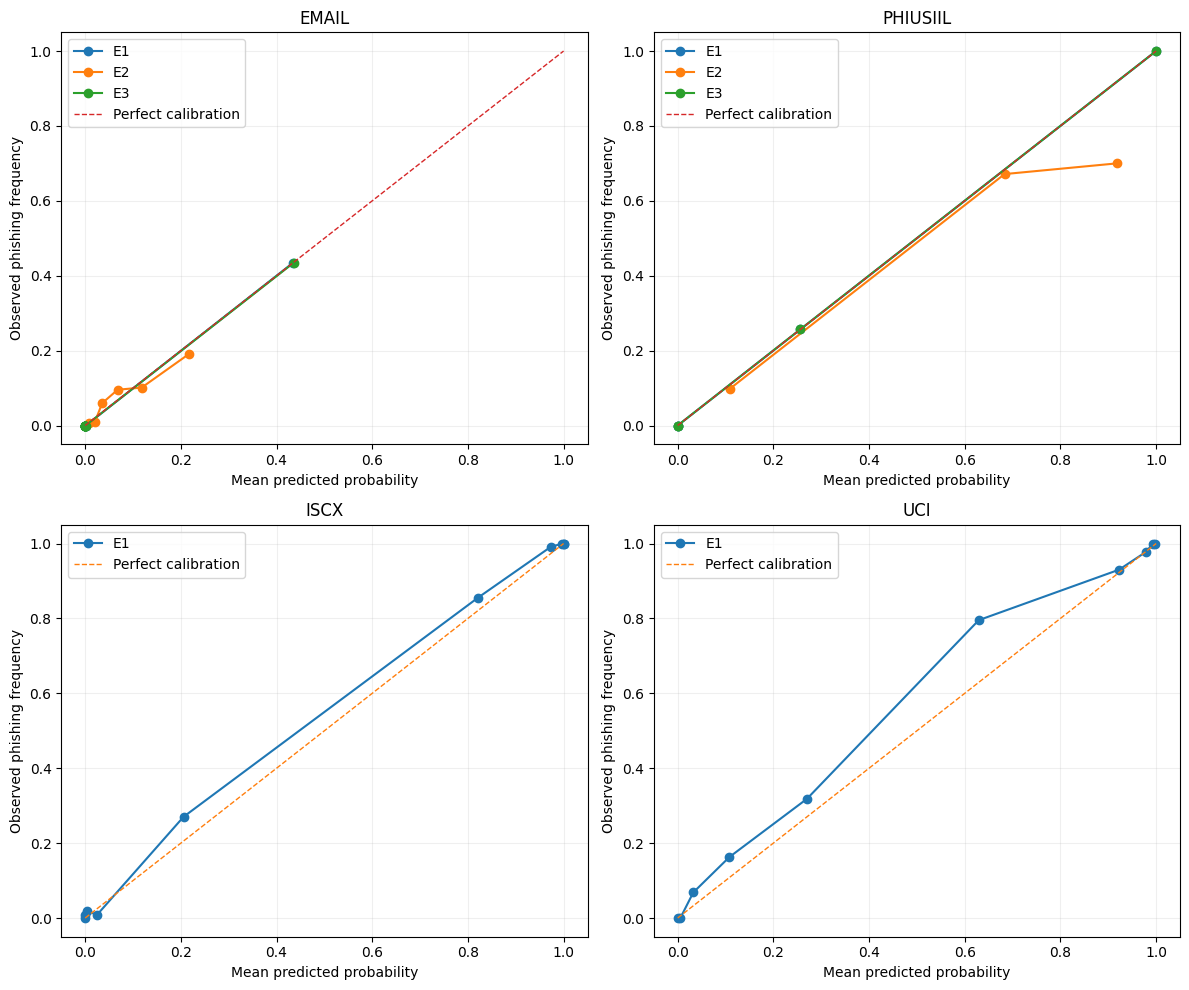

In [19]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
)

for ax, dataset_name in zip(
    axes.flat,
    DATASETS.keys(),
):
    df = frames[dataset_name]

    probability_subset, threshold_subset = (
        make_calibration_subsets(df)
    )

    y_true = threshold_subset["target"]

    for experiment in EXPERIMENTS[dataset_name]:
        fitted = FINAL_MODELS[
            (dataset_name, experiment)
        ]

        raw_scores = fitted[
            "estimator"
        ].predict_proba(
            threshold_subset
        )[:, 1]

        calibrated_scores = (
            apply_sigmoid_calibration(
                fitted["calibrator"],
                raw_scores,
            )
        )

        observed, predicted = calibration_curve(
            y_true,
            calibrated_scores,
            n_bins=10,
            strategy="quantile",
        )

        ax.plot(
            predicted,
            observed,
            marker="o",
            label=experiment,
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1,
        label="Perfect calibration",
    )

    ax.set_title(dataset_name.upper())
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed phishing frequency")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "calibration_reliability.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 16. Calibration Diagnostics

The reliability plots compare predicted probabilities against
observed phishing frequencies on the threshold-selection subsets.

For a well-calibrated model, observations assigned approximately
0.20 phishing probability should be phishing approximately
20% of the time, subject to sampling uncertainty.

### Interpretation

- A curve close to the diagonal indicates better agreement.
- Deviations above the diagonal suggest underestimation of risk
  within the corresponding probability bins.
- Deviations below the diagonal suggest overestimation.
- Sparse positive classes may produce unstable reliability bins.

The Brier score summarizes probability accuracy but does not
separately measure discrimination and calibration.

Calibration diagnostics are not used to repeatedly revise the
model after inspecting the final test results.

The selected probability transformation and threshold are now
frozen for final evaluation.

## 17. Final Holdout Test Evaluation

The test partition has been reserved throughout development,
cross-validation, model fitting, probability calibration,
and threshold selection.

This section performs the final evaluation using the frozen
model configurations.

### Evaluation Procedure

For each dataset and eligible experiment:

1. Load the predefined test partition.
2. Generate predictions using the development-trained model.
3. Apply the fitted sigmoid probability transformation.
4. Apply the threshold selected from calibration data.
5. Compute discrimination, classification, and probability metrics.
6. Export final metrics and prediction records.

### Fair Comparison

For Email and PhiUSIIL, E1, E2, and E3 are evaluated on the
same observations and ground-truth labels.

For ISCX and UCI, only E1 is evaluated.

### Interpretation Boundary

The final test represents held-out observations within the
available datasets.

It does not by itself demonstrate robustness to unseen
organizations, future phishing campaigns, domain shifts,
or live deployment environments.

Any further model modifications after inspecting this test
must be documented as exploratory and would require a new
independent evaluation set for confirmatory claims.

In [20]:
holdout_results = []
holdout_predictions = []

for dataset_name, experiment_names in EXPERIMENTS.items():
    df = frames[dataset_name]

    test = get_partition(
        df,
        "test",
    )

    for experiment in experiment_names:
        fitted = FINAL_MODELS[
            (dataset_name, experiment)
        ]

        estimator = fitted["estimator"]
        calibrator = fitted["calibrator"]
        threshold = fitted["threshold"]

        raw_probabilities = (
            estimator.predict_proba(test)[:, 1]
        )

        probabilities = (
            apply_sigmoid_calibration(
                calibrator,
                raw_probabilities,
            )
        )

        metrics = calculate_metrics(
            test["target"],
            probabilities,
            threshold=threshold,
        )

        metrics.update({
            "dataset": dataset_name,
            "experiment": experiment,
            "n_test": len(test),
        })

        holdout_results.append(metrics)

        predictions = pd.DataFrame({
            "dataset": dataset_name,
            "experiment": experiment,
            "observation_id": (
                test["observation_id"].values
            ),
            "group_id": (
                test["group_id"].values
            ),
            "target": (
                test["target"].values
            ),
            "probability": probabilities,
            "prediction": (
                probabilities >= threshold
            ).astype(int),
        })

        holdout_predictions.append(
            predictions
        )

holdout_results_df = pd.DataFrame(
    holdout_results
)

holdout_predictions_df = pd.concat(
    holdout_predictions,
    ignore_index=True,
)

display(
    holdout_results_df[
        [
            "dataset",
            "experiment",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "balanced_accuracy",
            "brier_score",
            "threshold",
        ]
    ].round(4)
)

holdout_results_df.to_csv(
    RESULTS_DIR / "holdout_test_metrics.csv",
    index=False,
)

holdout_predictions_df.to_csv(
    RESULTS_DIR / "holdout_predictions.csv",
    index=False,
)

print("Holdout evaluation completed.")

,dataset,experiment,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,brier_score,threshold
0,email,E1,0.9950,0.9997,0.9831,0.9872,0.9851,0.9933,0.0014,0.1961
1,email,E2,0.1570,0.8225,0.1833,0.4213,0.2555,0.6711,0.0357,0.1210
2,email,E3,0.9953,0.9997,0.9707,0.9872,0.9789,0.9930,0.0013,0.1754
3,phiusiil,E1,0.9999,0.9999,0.9999,0.9990,0.9994,0.9994,0.0004,0.6354
4,phiusiil,E2,0.6549,0.7897,0.6776,0.9052,0.7751,0.7893,0.1628,0.3842
5,phiusiil,E3,0.9999,0.9999,0.9999,0.9990,0.9994,0.9994,0.0004,0.6468
6,iscx,E1,0.9910,0.9921,0.9550,0.9734,0.9641,0.9647,0.0277,0.3690
7,uci,E1,0.9799,0.9783,0.9024,0.9335,0.9177,0.9169,0.0595,0.2916


Holdout evaluation completed.


In [21]:
primary_metrics = [
    "average_precision",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "brier_score",
]

comparison_rows = []

for dataset_name in ["email", "phiusiil"]:
    subset = (
        holdout_results_df
        .set_index(["dataset", "experiment"])
    )

    baseline = subset.loc[
        (dataset_name, "E1")
    ]

    for experiment in ["E2", "E3"]:
        candidate = subset.loc[
            (dataset_name, experiment)
        ]

        for metric in primary_metrics:
            comparison_rows.append({
                "dataset": dataset_name,
                "comparison": f"{experiment} vs E1",
                "metric": metric,
                "baseline_value": baseline[metric],
                "candidate_value": candidate[metric],
                "difference": (
                    candidate[metric]
                    - baseline[metric]
                ),
            })

holdout_comparisons = pd.DataFrame(
    comparison_rows
)

display(
    holdout_comparisons.round(4)
)

holdout_comparisons.to_csv(
    RESULTS_DIR / "holdout_comparisons.csv",
    index=False,
)

,dataset,comparison,metric,baseline_value,candidate_value,difference
0,email,E2 vs E1,average_precision,0.9950,0.1570,-0.8380
1,email,E2 vs E1,precision,0.9831,0.1833,-0.7997
2,email,E2 vs E1,recall,0.9872,0.4213,-0.5660
3,email,E2 vs E1,f1,0.9851,0.2555,-0.7297
4,email,E2 vs E1,roc_auc,0.9997,0.8225,-0.1772
5,email,E2 vs E1,brier_score,0.0014,0.0357,0.0343
6,email,E3 vs E1,average_precision,0.9950,0.9953,0.0002
7,email,E3 vs E1,precision,0.9831,0.9707,-0.0123
8,email,E3 vs E1,recall,0.9872,0.9872,0.0000
9,email,E3 vs E1,f1,0.9851,0.9789,-0.0062


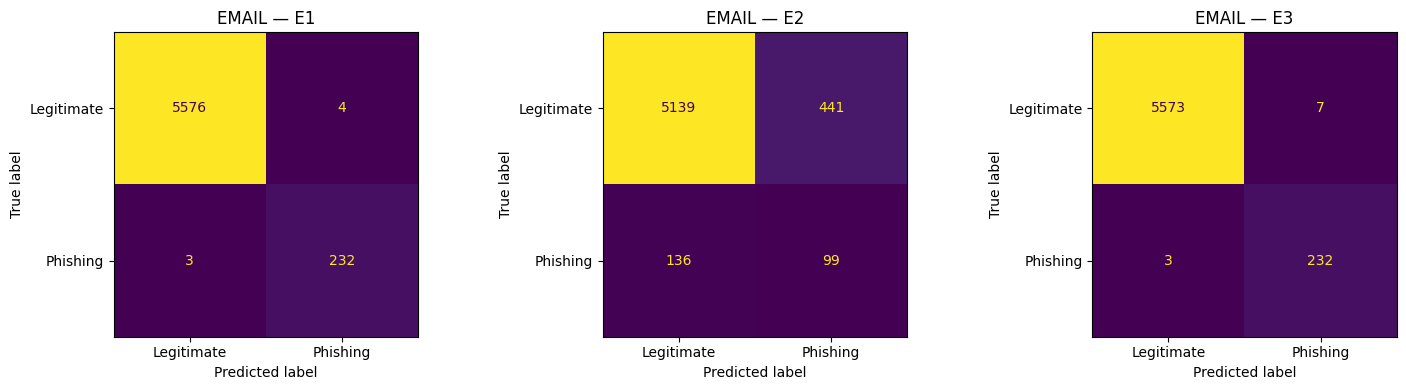

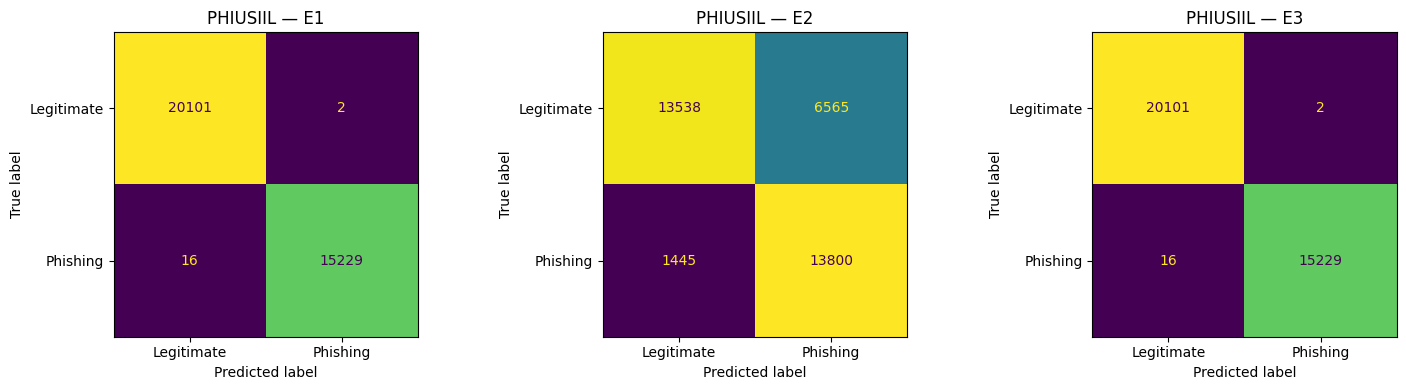

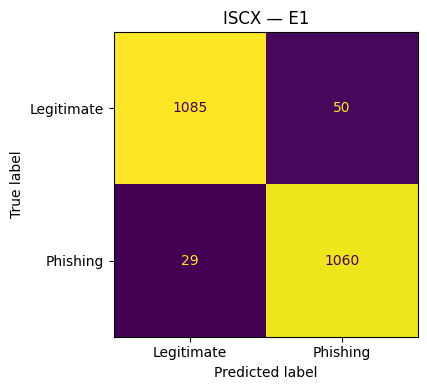

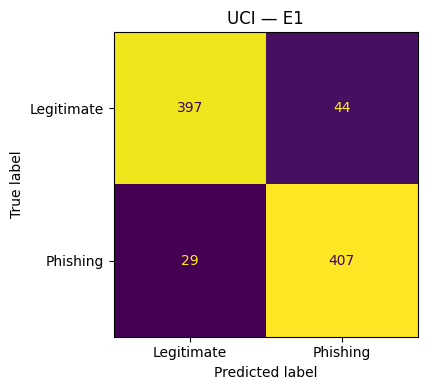

In [23]:
for dataset_name, experiment_names in EXPERIMENTS.items():
    fig, axes = plt.subplots(
        1,
        len(experiment_names),
        figsize=(5 * len(experiment_names), 4),
        squeeze=False,
    )

    for ax, experiment in zip(
        axes.flat,
        experiment_names,
    ):
        subset = holdout_predictions_df[
            (
                holdout_predictions_df["dataset"]
                == dataset_name
            )
            & (
                holdout_predictions_df["experiment"]
                == experiment
            )
        ]

        cm = confusion_matrix(
            subset["target"],
            subset["prediction"],
            labels=[0, 1],
        )

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "Legitimate",
                "Phishing",
            ],
        ).plot(
            ax=ax,
            colorbar=False,
            values_format="d",
        )

        ax.set_title(
            f"{dataset_name.upper()} — {experiment}"
        )

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR
        / f"{dataset_name}_confusion_matrices.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

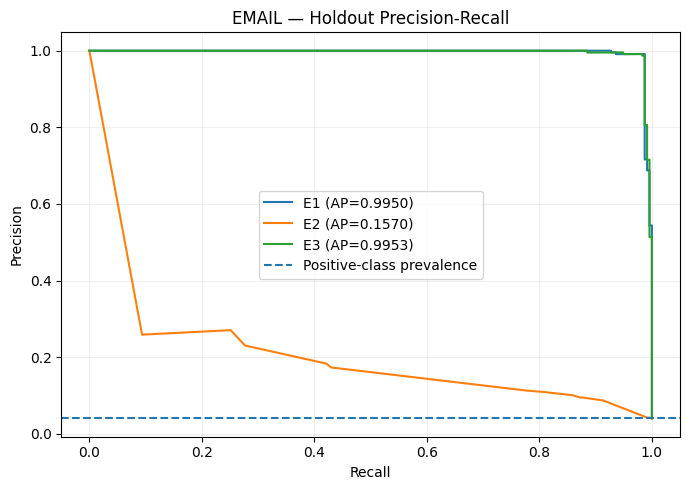

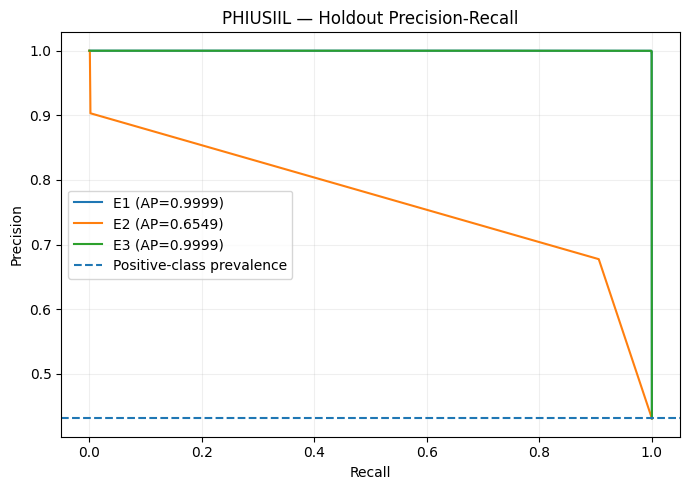

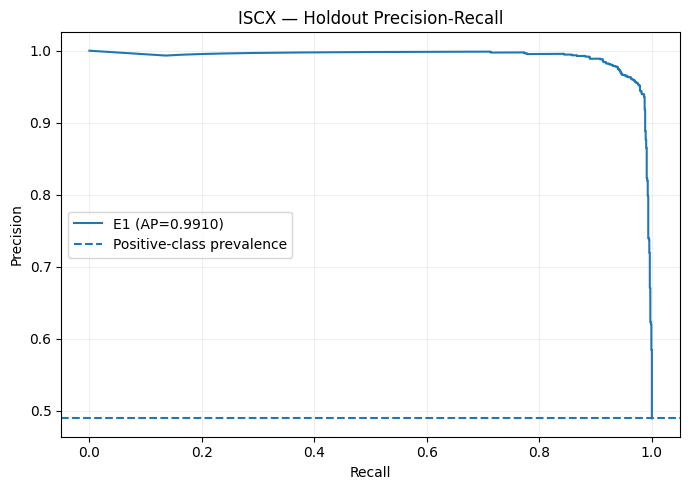

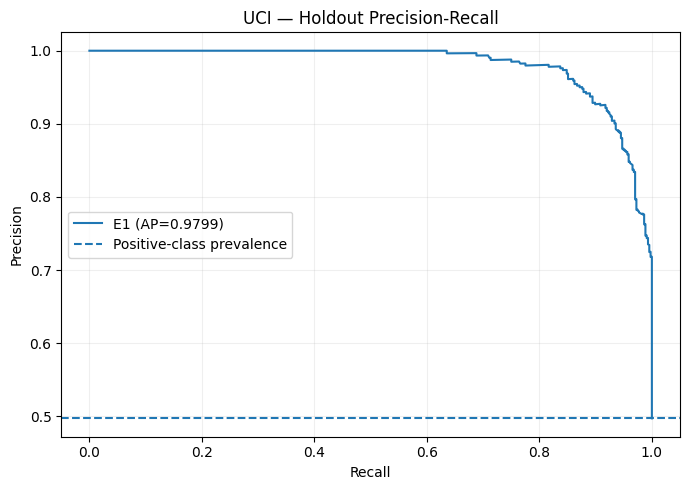

In [24]:
for dataset_name, experiment_names in EXPERIMENTS.items():
    plt.figure(figsize=(7, 5))

    for experiment in experiment_names:
        subset = holdout_predictions_df[
            (
                holdout_predictions_df["dataset"]
                == dataset_name
            )
            & (
                holdout_predictions_df["experiment"]
                == experiment
            )
        ]

        precision, recall, _ = (
            precision_recall_curve(
                subset["target"],
                subset["probability"],
            )
        )

        ap = average_precision_score(
            subset["target"],
            subset["probability"],
        )

        plt.plot(
            recall,
            precision,
            label=f"{experiment} (AP={ap:.4f})",
        )

    baseline_prevalence = (
        frames[dataset_name]
        .loc[
            frames[dataset_name]["partition"] == "test",
            "target",
        ]
        .mean()
    )

    plt.axhline(
        baseline_prevalence,
        linestyle="--",
        label="Positive-class prevalence",
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(
        f"{dataset_name.upper()} — Holdout Precision-Recall"
    )

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR
        / f"{dataset_name}_precision_recall.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

## 18. Final Performance Interpretation

The final test metrics provide the principal quantitative evidence
for the experimental research questions.

### RQ1 — Conventional Detection

E1 results establish the performance of modality-appropriate
conventional predictors.

### RQ2 — Behavioral Representation

E2 results assess whether the current rule-derived behavioral
representation can discriminate phishing from legitimate artifacts
within Email and PhiUSIIL.

### RQ3 — Incremental Value of Fusion

E3 versus E1 comparisons measure whether adding behavioral
features changes detection performance when the same classifier,
dataset, and partitions are used.

### RQ4 — Modality-Aware Evidence Availability

Evidence coverage and the omission of non-assessable E2/E3
configurations demonstrate how dataset information limits
the evaluation of behavioral representations.

### Important Reporting Requirements

- A positive performance difference is not automatically
  statistically significant.
- A high ROC-AUC does not guarantee high phishing precision
  under strong class imbalance.
- F1 results depend on the selected decision threshold.
- Average Precision depends partly on class prevalence.
- Low Brier scores require interpretation relative to
  baseline prevalence and calibration diagnostics.
- The observed results must not be generalized beyond
  the evaluated datasets without further validation.

The numerical results displayed above, rather than hypothetical
expectations, determine which hypotheses are supported.

## 19. SE-BRL Behavioral Dimension Ablation

Ablation analysis investigates the contribution of each behavioral
dimension to the fused model.

Four ablation configurations are evaluated:

- Remove Pressure / Threat.
- Remove Lure / Attention.
- Remove Trust / Identity.
- Remove Requested Action / Consequence.

Both the support and availability fields associated with a dimension
are removed together.

### Experimental Control

Ablation models use the same development folds, conventional
predictors, classifier, and evaluation metrics as E3.

Ablation is conducted on development data only.

This is important because ablation results must not be used
to modify the selected model after final test evaluation.

### Interpretation

If removing a dimension reduces Average Precision, that suggests
the dimension contributes useful predictive information under
the evaluated configuration.

However, correlated features can compensate for removed features.
A small ablation effect does not necessarily imply that a behavioral
dimension is conceptually unimportant.

The resulting effects are descriptive rather than causal.

In [25]:
BEHAVIORAL_DIMENSIONS = {
    "pressure_threat": [
        "pressure_threat_supported",
        "pressure_threat_available",
    ],
    "lure_attention": [
        "lure_attention_supported",
        "lure_attention_available",
    ],
    "trust_identity": [
        "trust_identity_supported",
        "trust_identity_available",
    ],
    "requested_action_consequence": [
        "requested_action_consequence_supported",
        "requested_action_consequence_available",
    ],
}


def make_ablation_pipeline(
    dataset_name,
    omitted_dimension,
):
    if omitted_dimension not in BEHAVIORAL_DIMENSIONS:
        raise ValueError(
            f"Unknown dimension: {omitted_dimension}"
        )

    omitted_columns = set(
        BEHAVIORAL_DIMENSIONS[omitted_dimension]
    )

    remaining_behavioral = [
        col
        for col in SEBRL_COLUMNS
        if col not in omitted_columns
    ]

    if dataset_name == "email":
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "text",
                    TfidfVectorizer(
                        max_features=20000,
                        ngram_range=(1, 2),
                        min_df=3,
                        sublinear_tf=True,
                        dtype=np.float32,
                    ),
                    "model_text",
                ),
                (
                    "behavioral",
                    "passthrough",
                    remaining_behavioral,
                ),
            ],
            remainder="drop",
            sparse_threshold=1.0,
        )

    else:
        columns = (
            CONVENTIONAL_COLUMNS[dataset_name]
            + remaining_behavioral
        )

        preprocessor = make_numeric_transformer(
            columns
        )

    return Pipeline([
        ("preprocessing", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_SEED,
                solver="liblinear",
            ),
        ),
    ])

In [26]:
ablation_results = []

for dataset_name in ["email", "phiusiil"]:
    df = frames[dataset_name]

    development = get_partition(
        df,
        "development",
    )

    for omitted_dimension in BEHAVIORAL_DIMENSIONS:
        print(
            f"\n{dataset_name}: removing "
            f"{omitted_dimension}"
        )

        for fold in range(1, 6):
            training = development[
                development["cv_fold"] != fold
            ]

            validation = development[
                development["cv_fold"] == fold
            ]

            model = make_ablation_pipeline(
                dataset_name,
                omitted_dimension,
            )

            model.fit(
                training,
                training["target"],
            )

            probabilities = model.predict_proba(
                validation
            )[:, 1]

            metrics = calculate_metrics(
                validation["target"],
                probabilities,
                threshold=0.5,
            )

            ablation_results.append({
                "dataset": dataset_name,
                "omitted_dimension": omitted_dimension,
                "fold": fold,
                **metrics,
            })

ablation_df = pd.DataFrame(
    ablation_results
)

ablation_summary = (
    ablation_df
    .groupby(
        ["dataset", "omitted_dimension"]
    )[
        ["average_precision", "f1", "recall"]
    ]
    .agg(["mean", "std"])
)

ablation_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in ablation_summary.columns
]

ablation_summary = (
    ablation_summary.reset_index()
)

display(ablation_summary.round(4))

ablation_df.to_csv(
    RESULTS_DIR / "ablation_fold_metrics.csv",
    index=False,
)

ablation_summary.to_csv(
    RESULTS_DIR / "ablation_summary.csv",
    index=False,
)


email: removing pressure_threat

email: removing lure_attention

email: removing trust_identity

email: removing requested_action_consequence

phiusiil: removing pressure_threat

phiusiil: removing lure_attention

phiusiil: removing trust_identity

phiusiil: removing requested_action_consequence


,dataset,omitted_dimension,average_precision_mean,average_precision_std,f1_mean,f1_std,recall_mean,recall_std
0,email,lure_attention,0.9920,0.0053,0.9589,0.0119,0.9781,0.0189
1,email,pressure_threat,0.9919,0.0055,0.9615,0.0121,0.9781,0.0203
2,email,requested_action_consequence,0.9926,0.0048,0.9626,0.0093,0.9753,0.0179
3,email,trust_identity,0.9919,0.0053,0.9588,0.0070,0.9763,0.0192
4,phiusiil,lure_attention,1.0000,0.0000,0.9994,0.0002,0.9991,0.0004
5,phiusiil,pressure_threat,1.0000,0.0000,0.9994,0.0002,0.9991,0.0004
6,phiusiil,requested_action_consequence,1.0000,0.0000,0.9994,0.0002,0.9991,0.0004
7,phiusiil,trust_identity,1.0000,0.0000,0.9994,0.0002,0.9991,0.0004


In [27]:
ablation_comparisons = []

for dataset_name in ["email", "phiusiil"]:
    full_e3 = cv_results_df[
        (cv_results_df["dataset"] == dataset_name)
        & (cv_results_df["experiment"] == "E3")
    ].set_index("fold")

    for dimension in BEHAVIORAL_DIMENSIONS:
        ablated = ablation_df[
            (ablation_df["dataset"] == dataset_name)
            & (
                ablation_df["omitted_dimension"]
                == dimension
            )
        ].set_index("fold")

        for fold in range(1, 6):
            ablation_comparisons.append({
                "dataset": dataset_name,
                "omitted_dimension": dimension,
                "fold": fold,
                "full_e3_ap": full_e3.loc[
                    fold,
                    "average_precision",
                ],
                "ablated_ap": ablated.loc[
                    fold,
                    "average_precision",
                ],
                "ap_change_after_removal": (
                    ablated.loc[
                        fold,
                        "average_precision",
                    ]
                    - full_e3.loc[
                        fold,
                        "average_precision",
                    ]
                ),
            })

ablation_comparison_df = pd.DataFrame(
    ablation_comparisons
)

ablation_effects = (
    ablation_comparison_df
    .groupby(
        ["dataset", "omitted_dimension"]
    )["ap_change_after_removal"]
    .agg(["mean", "std"])
    .reset_index()
)

display(ablation_effects.round(5))

ablation_effects.to_csv(
    RESULTS_DIR / "ablation_effects.csv",
    index=False,
)

,dataset,omitted_dimension,mean,std
0,email,lure_attention,0.00018,0.00043
1,email,pressure_threat,0.00013,0.00011
2,email,requested_action_consequence,0.00081,0.00106
3,email,trust_identity,0.00013,0.00043
4,phiusiil,lure_attention,0.00000,0.00000
5,phiusiil,pressure_threat,-0.00000,0.00000
6,phiusiil,requested_action_consequence,0.00000,0.00000
7,phiusiil,trust_identity,-0.00000,0.00000


## 20. Model Explainability

The experimental classifiers use logistic regression, allowing
inspection of fitted feature coefficients.

For standardized numerical features, coefficients indicate the
direction of association with the model's predicted log-odds,
conditional on the other included predictors.

For TF-IDF text features, coefficients describe associations
between learned terms and the classifier's prediction.

### Interpretation Rules

- Positive coefficients increase the modeled log-odds of class 1.
- Negative coefficients decrease the modeled log-odds of class 1.
- Coefficient magnitude depends on feature representation,
  regularization, and correlations among predictors.
- Coefficients do not establish causal relationships.
- Logistic regression coefficients are not automatically
  human-readable explanations of social engineering intent.

The explanation analysis focuses on feature transparency,
not on proving that model decisions are causally explained.

A full artifact-level explanation system and risk-adaptive
defense mechanism would require additional implementation
and evaluation outside the scope of this notebook.

In [28]:
def extract_coefficients(
    dataset_name,
    experiment,
):
    fitted = FINAL_MODELS[
        (dataset_name, experiment)
    ]

    estimator = fitted["estimator"]
    preprocessor = estimator.named_steps[
        "preprocessing"
    ]

    classifier = estimator.named_steps[
        "classifier"
    ]

    feature_names = (
        preprocessor.get_feature_names_out()
    )

    coefficients = classifier.coef_[0]

    if len(feature_names) != len(coefficients):
        raise ValueError(
            "Feature-name and coefficient counts differ"
        )

    return pd.DataFrame({
        "dataset": dataset_name,
        "experiment": experiment,
        "feature": feature_names,
        "coefficient": coefficients,
        "absolute_coefficient": np.abs(
            coefficients
        ),
    })


coefficient_tables = []

for dataset_name, experiment_names in EXPERIMENTS.items():
    for experiment in experiment_names:
        coefficient_tables.append(
            extract_coefficients(
                dataset_name,
                experiment,
            )
        )

coefficients_df = pd.concat(
    coefficient_tables,
    ignore_index=True,
)

coefficients_df.to_csv(
    RESULTS_DIR / "model_coefficients.csv",
    index=False,
)

for dataset_name in ["email", "phiusiil"]:
    subset = coefficients_df[
        (coefficients_df["dataset"] == dataset_name)
        & (
            coefficients_df["experiment"] == "E3"
        )
    ]

    behavioral_coefficients = subset[
        subset["feature"].str.contains(
            "supported|available",
            case=False,
            regex=True,
        )
    ]

    print(
        f"\n{dataset_name.upper()} — "
        "SE-BRL coefficients"
    )

    display(
        behavioral_coefficients[
            ["feature", "coefficient"]
        ].sort_values(
            "coefficient",
            ascending=False,
        ).round(5)
    )


EMAIL — SE-BRL coefficients


,feature,coefficient
40011,behavioral__requested_action_consequence_suppo...,0.87103
40008,behavioral__pressure_threat_supported,0.59749
40010,behavioral__trust_identity_supported,0.55615
22954,text__available for,0.22957
31718,text__now available,0.20695
23105,text__be available,0.02801
22527,text__are available,0.00929
22956,text__available in,-0.01715
22953,text__available at,-0.04162
22952,text__available and,-0.04201



PHIUSIIL — SE-BRL coefficients


,feature,coefficient
40120,numeric__trust_identity_supported,0.02699
40118,numeric__pressure_threat_supported,0.01979
40122,numeric__pressure_threat_available,0.00000
40123,numeric__lure_attention_available,0.00000
40124,numeric__trust_identity_available,0.00000
40125,numeric__requested_action_consequence_available,0.00000
40119,numeric__lure_attention_supported,-0.03023
40121,numeric__requested_action_consequence_supported,-0.10624


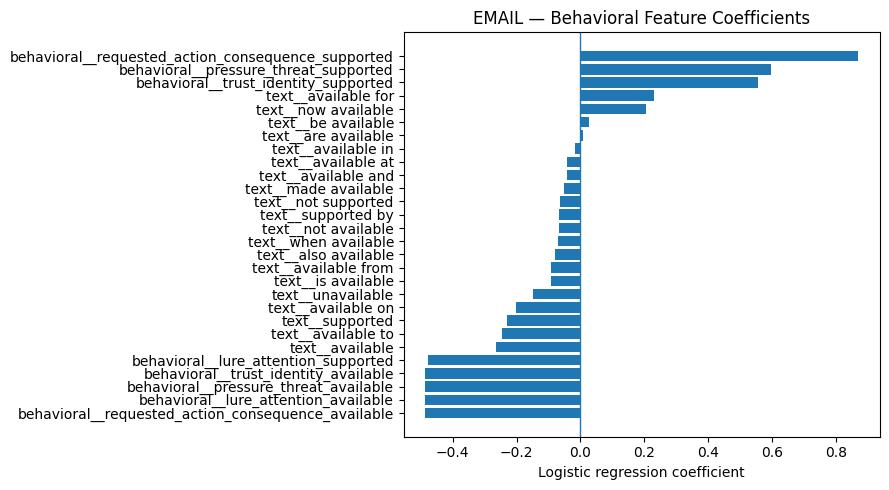

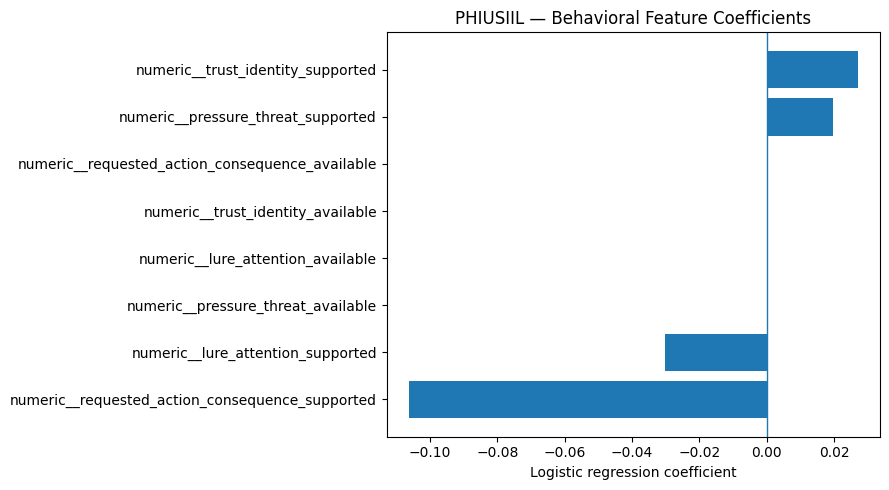

In [29]:
for dataset_name in ["email", "phiusiil"]:
    subset = coefficients_df[
        (coefficients_df["dataset"] == dataset_name)
        & (
            coefficients_df["experiment"] == "E3"
        )
    ]

    behavioral = subset[
        subset["feature"].str.contains(
            "supported|available",
            regex=True,
        )
    ].sort_values(
        "coefficient"
    )

    plt.figure(figsize=(9, 5))

    plt.barh(
        behavioral["feature"],
        behavioral["coefficient"],
    )

    plt.axvline(
        0,
        linewidth=1,
    )

    plt.title(
        f"{dataset_name.upper()} — "
        "Behavioral Feature Coefficients"
    )

    plt.xlabel(
        "Logistic regression coefficient"
    )

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR
        / f"{dataset_name}_behavioral_coefficients.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

## 21. Classification Error Analysis

Error analysis examines the types and distribution of incorrect
predictions.

Two error categories are particularly important:

**False positives:** Legitimate artifacts incorrectly classified
as phishing.

**False negatives:** Phishing artifacts incorrectly classified
as legitimate.

False positives may cause unnecessary alerts and operational
disruption.

False negatives may permit harmful social engineering attempts
to pass undetected.

### Analysis Boundaries

The analysis uses predictions and metadata rather than displaying
raw malicious URLs or potentially sensitive email contents.

It provides descriptive failure counts and confidence summaries.

The test errors are analyzed after the holdout models have been
frozen. Findings from this analysis are intended for discussion
and future research, not retrospective modification of the
reported experimental results.

In [30]:
error_records = []

for (dataset_name, experiment), subset in (
    holdout_predictions_df.groupby(
        ["dataset", "experiment"]
    )
):
    true_values = subset["target"].to_numpy()
    predictions = subset["prediction"].to_numpy()
    probabilities = subset["probability"].to_numpy()

    false_positives = (
        (true_values == 0)
        & (predictions == 1)
    )

    false_negatives = (
        (true_values == 1)
        & (predictions == 0)
    )

    error_records.append({
        "dataset": dataset_name,
        "experiment": experiment,
        "false_positives": int(
            false_positives.sum()
        ),
        "false_negatives": int(
            false_negatives.sum()
        ),
        "mean_fp_probability": (
            float(probabilities[false_positives].mean())
            if false_positives.any()
            else np.nan
        ),
        "mean_fn_probability": (
            float(probabilities[false_negatives].mean())
            if false_negatives.any()
            else np.nan
        ),
    })

error_summary = pd.DataFrame(
    error_records
)

display(error_summary.round(4))

error_summary.to_csv(
    RESULTS_DIR / "error_analysis_summary.csv",
    index=False,
)

,dataset,experiment,false_positives,false_negatives,mean_fp_probability,mean_fn_probability
0,email,E1,4,3,0.4889,0.0086
1,email,E2,441,136,0.1653,0.0507
2,email,E3,7,3,0.3800,0.0121
3,iscx,E1,50,29,0.6760,0.1732
4,phiusiil,E1,2,16,0.8407,0.2061
5,phiusiil,E2,6565,1445,0.6836,0.1103
6,phiusiil,E3,2,16,0.8320,0.2085
7,uci,E1,44,29,0.5740,0.1418


## 22. Reproducibility and Result Preservation

This experiment uses fixed data partitions, predefined development
folds, controlled random seeds, and explicit feature exclusions.

The notebook exports intermediate and final experimental results
to allow independent inspection and thesis reporting.

### Reproducibility Requirements

A reproducible run should preserve:

1. Input dataset filenames and content hashes.
2. Dataset dimensions and label distributions.
3. Partition and cross-validation integrity results.
4. Model configurations and random seeds.
5. Evaluation metrics and decision thresholds.
6. Probability calibration diagnostics.
7. Model coefficients and ablation summaries.
8. Software versions and execution timestamps.

### Important Limitations

The notebook records experimental settings and outputs but does
not by itself guarantee reproducibility across different software,
hardware, or dependency versions.

Exact reproduction requires the same input files, compatible
dependencies, and documented preprocessing pipeline.

Results should be interpreted in conjunction with the methods,
feature extraction rules, and dataset limitations documented
in the preceding notebooks.

In [31]:
import hashlib
import platform
import sklearn
from datetime import datetime, timezone


def calculate_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(1024 * 1024)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


input_manifest = []

for dataset_name, config in DATASETS.items():
    for input_type, directory, filename in [
        (
            "preprocessed",
            PREPROCESSED_DIR,
            config["preprocessed"],
        ),
        (
            "behavioral",
            SEBRL_DIR,
            config["behavioral"],
        ),
    ]:
        path = directory / filename

        input_manifest.append({
            "dataset": dataset_name,
            "input_type": input_type,
            "filename": filename,
            "sha256": calculate_sha256(path),
        })

input_manifest_df = pd.DataFrame(
    input_manifest
)

input_manifest_df.to_csv(
    RESULTS_DIR / "input_manifest.csv",
    index=False,
)

experiment_manifest = {
    "notebook": "05_experiments.ipynb",
    "research_project": "SE-BRL",
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "random_seed": RANDOM_SEED,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "datasets": list(DATASETS.keys()),
    "experiments": EXPERIMENTS,
    "classifier": "LogisticRegression",
    "class_weight": "balanced",
    "cross_validation": {
        "folds": 5,
        "fold_source": "Notebook 03",
        "group_aware": True,
    },
    "calibration": {
        "method": "sigmoid_on_logit_scores",
        "probability_subset": "group-separated calibration subset",
        "threshold_subset": "group-separated calibration subset",
        "threshold_objective": "maximize_f1",
    },
    "primary_metric": "average_precision",
    "behavioral_representation": (
        "rule_derived_dimension_level_features"
    ),
    "phiusiil_excluded_columns": sorted(
        PHIUSIIL_PROVENANCE_EXCLUSIONS
    ),
    "conventional_features": CONVENTIONAL_COLUMNS,
}

with open(
    RESULTS_DIR / "experiment_manifest.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        experiment_manifest,
        file,
        indent=2,
    )

print("Experiment manifest saved.")
display(input_manifest_df)

Experiment manifest saved.


,dataset,input_type,filename,sha256
0,email,preprocessed,email_preprocessed.csv,4478a4972bbc11cf5d0447ef80b1f2fdfda396290ba4d7...
1,email,behavioral,email_sebrl_features.csv,e704fd8cdb7cfe6ecada601d984ca58589de259328dfd0...
2,phiusiil,preprocessed,phiusiil_preprocessed.csv,1e090bc2167dfd799e38e461342594373fcde85117492f...
3,phiusiil,behavioral,phiusiil_sebrl_features.csv,edee73c21e2fdf90b008e14549f3720e6d7df65276d8a0...
4,iscx,preprocessed,iscx_url2016_preprocessed.csv,298b5891bd0ea7fa86e50e0b3c73798b9bef6f1bf74d26...
5,iscx,behavioral,iscx_sebrl_features.csv,e59a4d381a71999066d90a94f970a987ba215f8972f354...
6,uci,preprocessed,uci_phishing_websites_preprocessed.csv,e5558bced50e80b3133ea3c60ac7f062c5c02fa0bb3ce9...
7,uci,behavioral,uci_sebrl_features.csv,c7f039c60910d2d026692305aed238a127839cfd8e37d9...


## 23. Synthesis of Experimental Findings

The final results must be synthesized according to the four
research questions established at the beginning of the notebook.

### RQ1: Conventional Phishing Detection

Discuss the performance of E1 across the four datasets.

Report Average Precision, ROC-AUC, F1, precision, recall,
and probability accuracy, while accounting for class prevalence.

### RQ2: Behavioral Representation Utility

Discuss E2 for Email and PhiUSIIL.

Identify whether the behavioral features provide predictive
discrimination and whether results vary across modalities.

Do not extend E2 conclusions to ISCX or UCI because their
behavioral evidence is unavailable.

### RQ3: Incremental Contribution of SE-BRL Fusion

Compare E3 with E1 on matched Email and PhiUSIIL test records.

Report the absolute differences in the primary and secondary
metrics rather than asserting that fusion improves performance.

Use the development-fold comparisons and ablation results to
provide supplementary descriptive context.

### RQ4: Modality-Aware Evidence Limitations

Discuss the distinction between available, supported, and absent
behavioral evidence.

Explain why the present representation is assessable on Email
and PhiUSIIL but not on ISCX and UCI.

### Research Interpretation

The conclusions must distinguish:

- Empirically observed detection performance.
- Incremental predictive contribution of behavioral features.
- Dataset-specific or modality-specific limitations.
- Methodological choices not yet independently validated.
- Capabilities implemented in the broader SE-BRL architecture
  but not experimentally assessed here.

The final claims should be limited to what the results support.

In [32]:
print("=" * 70)
print("SE-BRL EXPERIMENTAL RESULTS SUMMARY")
print("=" * 70)

for dataset_name in DATASETS:
    print(f"\nDATASET: {dataset_name.upper()}")

    subset = holdout_results_df[
        holdout_results_df["dataset"]
        == dataset_name
    ]

    for _, row in subset.iterrows():
        print(
            f"  {row['experiment']}: "
            f"AP={row['average_precision']:.4f}, "
            f"F1={row['f1']:.4f}, "
            f"Recall={row['recall']:.4f}, "
            f"Precision={row['precision']:.4f}, "
            f"Brier={row['brier_score']:.4f}"
        )

    if dataset_name in ["email", "phiusiil"]:
        e1 = subset[
            subset["experiment"] == "E1"
        ].iloc[0]

        e3 = subset[
            subset["experiment"] == "E3"
        ].iloc[0]

        ap_difference = (
            e3["average_precision"]
            - e1["average_precision"]
        )

        f1_difference = (
            e3["f1"]
            - e1["f1"]
        )

        print(
            f"  E3 - E1 AP difference: "
            f"{ap_difference:+.4f}"
        )

        print(
            f"  E3 - E1 F1 difference: "
            f"{f1_difference:+.4f}"
        )

        if ap_difference > 0:
            print(
                "  Observation: fusion achieved "
                "higher holdout Average Precision."
            )

        elif ap_difference < 0:
            print(
                "  Observation: fusion achieved "
                "lower holdout Average Precision."
            )

        else:
            print(
                "  Observation: fusion and baseline "
                "had equal reported Average Precision."
            )

    else:
        print(
            "  Behavioral experiments not evaluated: "
            "SE-BRL evidence unavailable."
        )

print("\n" + "=" * 70)
print("FINAL REPORTING NOTE")
print("=" * 70)

print(
    "These findings concern rule-derived behavioral "
    "features and the evaluated datasets."
)

print(
    "They do not establish performance for a learned "
    "behavioral predictor or a deployed defense system."
)

SE-BRL EXPERIMENTAL RESULTS SUMMARY

DATASET: EMAIL
  E1: AP=0.9950, F1=0.9851, Recall=0.9872, Precision=0.9831, Brier=0.0014
  E2: AP=0.1570, F1=0.2555, Recall=0.4213, Precision=0.1833, Brier=0.0357
  E3: AP=0.9953, F1=0.9789, Recall=0.9872, Precision=0.9707, Brier=0.0013
  E3 - E1 AP difference: +0.0002
  E3 - E1 F1 difference: -0.0062
  Observation: fusion achieved higher holdout Average Precision.

DATASET: PHIUSIIL
  E1: AP=0.9999, F1=0.9994, Recall=0.9990, Precision=0.9999, Brier=0.0004
  E2: AP=0.6549, F1=0.7751, Recall=0.9052, Precision=0.6776, Brier=0.1628
  E3: AP=0.9999, F1=0.9994, Recall=0.9990, Precision=0.9999, Brier=0.0004
  E3 - E1 AP difference: +0.0000
  E3 - E1 F1 difference: +0.0000
  Observation: fusion achieved higher holdout Average Precision.

DATASET: ISCX
  E1: AP=0.9910, F1=0.9641, Recall=0.9734, Precision=0.9550, Brier=0.0277
  Behavioral experiments not evaluated: SE-BRL evidence unavailable.

DATASET: UCI
  E1: AP=0.9799, F1=0.9177, Recall=0.9335, Precisio

## 24. Limitations

### 24.1 Behavioral Representation

The SE-BRL features evaluated in this notebook are generated
through deterministic extraction rules.

Although they encode behavioral evidence, they are not outputs
from a separately trained behavioral prediction model.

Therefore, this experiment does not validate the predictive
accuracy of twelve individual social engineering indicators.

### 24.2 Annotation Validity

Rule-derived behavioral evidence has not been established as
equivalent to independently annotated behavioral ground truth.

Independent expert annotation and inter-annotator agreement
would strengthen construct validity.

### 24.3 Dataset Coverage

The Email and PhiUSIIL datasets provide assessable behavioral
features, while ISCX and UCI currently do not.

This limits comparative behavioral evaluation across modalities.

### 24.4 Feature Quality and Provenance

Some conventional dataset features may depend on historical
reference information, dataset-specific transformations, or
external corpus statistics.

The present evaluation uses conservative exclusions for selected
PhiUSIIL predictors, but complete provenance verification
remains necessary.

### 24.5 Generalizability

Performance on held-out observations from the same source datasets
does not guarantee equivalent performance on future phishing
campaigns, unseen organizations, or deployment distributions.

### 24.6 Explainability

Logistic regression coefficients provide model transparency,
but do not establish causal explanations of phishing intent.

More comprehensive explanations require artifact-level evidence
tracing and independent human evaluation.

### 24.7 Risk-Adaptive Defense

The present notebook evaluates phishing classification performance.

It does not experimentally validate the complete risk-adaptive
defense workflow, including user-facing interventions,
extension behavior, latency, or operational safety.

## 25. Future Experimental Extensions

Recommended future work includes:

1. Independently annotated behavioral indicator labels.
2. Learned behavioral indicator prediction models.
3. Out-of-fold behavioral prediction for E2 and E3.
4. Additional model families and robust hyperparameter tuning.
5. Independent external-dataset validation.
6. Group-aware uncertainty estimates.
7. Artifact-level explanation fidelity testing.
8. Risk-adaptive intervention effectiveness testing.

Future experiments should preserve clear separation between
model development, model selection, calibration, and confirmatory
evaluation.

## 26. Conclusion

This notebook establishes a reproducible experimental framework
for assessing the predictive utility of conventional and rule-derived
SE-BRL behavioral features in phishing detection.

The study compares:

- E1: Conventional feature-based classification.
- E2: Rule-derived behavioral representation classification.
- E3: Conventional and behavioral feature fusion.

The evaluation uses predefined group-aware partitions,
five-fold development cross-validation, separate probability
calibration and threshold-selection subsets, and a final
held-out test partition.

Behavioral evaluations are limited to datasets containing
assessable evidence.

The experimental results, together with the feature coverage,
ablation, calibration, and error analyses, provide quantitative
material for the thesis Results and Discussion chapter.

Conclusions about whether SE-BRL improves phishing detection
must be based on the generated results.

Further validation is required before extending these findings
to learned behavioral prediction, cross-distribution robustness,
or deployed risk-adaptive defense.

**End of Notebook 05 — Comparative Modeling, Calibration, and Evaluation**